In [1]:
import numpy as np

data=np.load('data.npy')
target=np.load('target.npy')

#loading the save numpy arrays in the previous code

In [2]:
data.shape

(24997, 50, 50, 1)

In [3]:
target.shape

(24997, 2)

In [4]:
from keras.models import Sequential
from keras.layers import Dense,Activation,Flatten
from keras.layers import Conv2D,MaxPooling2D,Dropout,BatchNormalization
from keras.optimizers import Adam

model=Sequential()
#weight initialization-NN eka traing vima phasu karai(api normal distribution eka ena paridi weights,baises adjust karai)
#ex: kernel_initializer = 'orthogonal' -#uda  thiyenava kernel_initializer methods
model.add(Conv2D(32,(3,3),input_shape=data.shape[1:],kernel_initializer = 'orthogonal'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
#The first CNN layer followed by Relu and MaxPooling layers

model.add(Conv2D(64,(3,3),kernel_initializer = 'orthogonal'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
#The second convolution layer followed by Relu and MaxPooling layers

model.add(Conv2D(128,(3,3),kernel_initializer = 'orthogonal'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2)))



model.add(Flatten())
#Flatten layer to stack the output convolutions from third convolution layer
model.add(Dense(128,activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(64,activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(2,activation='softmax'))
#The Final layer with two outputs for two categories

#model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])
model.compile(loss='categorical_crossentropy',optimizer=Adam(learning_rate=0.0001),metrics=['accuracy'])        
#optimizer=Adam(learning_rate=0.0001) kiyla learning rate eka hadala(adu krl) dannath puluvn
model.summary()

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 22, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 22, 22, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 9, 9, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 9, 9, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 364,226 (1.39 MB)

 Trainable params: 363,778 (1.39 MB)

 Non-trainable params: 448 (1.75 KB)

In [5]:
from sklearn.model_selection import train_test_split

train_data,test_data,train_target,test_target=train_test_split(data,target,test_size=0.2,random_state=42)
#random_state=42 : code eka run vena hama parama dataset eka ahabu vidiyt split vima navathvimata

## Augmentation

In [6]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

aug = ImageDataGenerator(rotation_range=20,zoom_range=0.15,width_shift_range=0.2,height_shift_range=0.2,shear_range=0.15,
                         horizontal_flip=True,fill_mode="nearest")

In [7]:
from keras.callbacks import ModelCheckpoint
checkpoint = ModelCheckpoint('models/model-{epoch:03d}.weights.h5',monitor='val_loss',save_best_only=True,save_weights_only=True,mode='min')

In [8]:
from keras.callbacks import  EarlyStopping
# use EarlyStopping for stoping Overfitting
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20, # Validation loss එක epochs 20ක් තිස්සේ අඩු නොවුණොත් stop වේ
    restore_best_weights=True # හොඳම weights ටික model එකට තබා ගනී
)

In [9]:
from keras.callbacks import  ReduceLROnPlateau

# Validation loss එක අඩු නොවී නතර වෙන්න හදනකොට ස්වයංක්‍රීයව learning rate එක අඩු කරන්න මේ callback එක භාවිත කරන්න පුළුවන්:
#Training එක අතරතුර Epochs 3ක් තිස්සේ Validation Loss එක පහළ බැස්සේ නැත්නම්, මේ reduce_lr එකෙන් Auto Learning Rate එක 
# 0.4 කින් අඩු කරලා Model එකට තවත් හෙමින් Patterns ඉගෙන ගන්න ඉඩ සලසනවා. එතකොට Graph එකේ තියෙන zig-zag ගතිය නැතිවෙලා Smooth වෙනවා.
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.4, 
    patience=3, 
    #min_lr=1e-6
)

### Training the CNN for 10 epochs using train data 

In [10]:
import math

bs=32

history=model.fit(aug.flow(train_data,train_target,batch_size=bs),steps_per_epoch=math.ceil(len(train_data)/bs),
                  validation_data=(test_data,test_target),validation_steps=math.ceil(len(test_data)/bs),epochs=200,callbacks=[checkpoint,early_stop,reduce_lr])

Epoch 1/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 45s 68ms/step - accuracy: 0.5446 - loss: 0.7160 - val_accuracy: 0.6222 - val_loss: 0.6548 - learning_rate: 1.0000e-04
Epoch 2/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 46s 73ms/step - accuracy: 0.5902 - loss: 0.6672 - val_accuracy: 0.5878 - val_loss: 0.6611 - learning_rate: 1.0000e-04
Epoch 3/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 45s 73ms/step - accuracy: 0.6067 - loss: 0.6593 - val_accuracy: 0.5874 - val_loss: 0.6628 - learning_rate: 1.0000e-04
Epoch 4/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 46s 73ms/step - accuracy: 0.6166 - loss: 0.6508 - val_accuracy: 0.6484 - val_loss: 0.6210 - learning_rate: 1.0000e-04
Epoch 5/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 44s 71ms/step - accuracy: 0.6364 - loss: 0.6394 - val_accuracy: 0.6346 - val_loss: 0.6265 - learning_rate: 1.0000e-04
Epoch 6/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 45s 71ms/step - accuracy: 0.6459 - loss: 0.6284 - val_accuracy: 0.6550 - val_loss: 0.6038 - learning_rate: 1.0000e-04
Epoch 7/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 45s 7

### Visualizing the loss and the accuracy of trained CNN

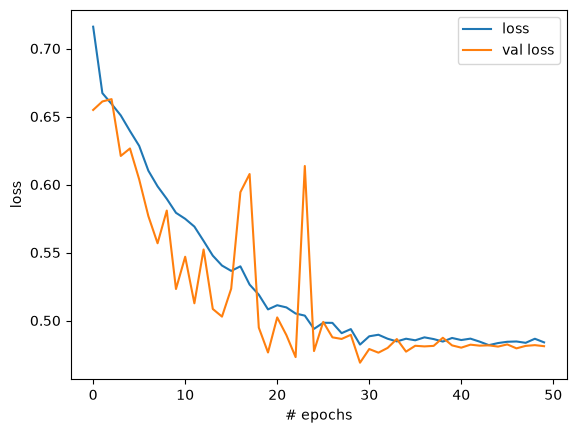

In [11]:
from matplotlib import pyplot as plt

plt.plot(history.history['loss'],label='loss')
plt.plot(history.history['val_loss'],label='val loss')
plt.legend()
plt.xlabel('# epochs')
plt.ylabel('loss')
plt.show()

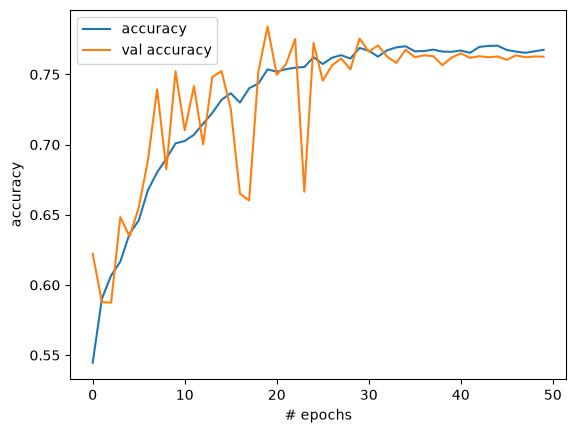

In [12]:
from matplotlib import pyplot as plt

plt.plot(history.history['accuracy'],label='accuracy')
plt.plot(history.history['val_accuracy'],label='val accuracy')
plt.legend()
plt.xlabel('# epochs')
plt.ylabel('accuracy')
plt.show()

### Evaluating the CNN using testing_data

This returns the loss and the accuracy of the Neural Network for Testing data

In [13]:
print(model.evaluate(test_data,test_target))

157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7756 - loss: 0.4690
[0.46901172399520874, 0.775600016117096]


In [14]:
predicted_target=model.predict(test_data)

157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step


In [15]:
from sklearn.metrics import classification_report

classification_report(np.argmax(test_target,axis=1),np.argmax(predicted_target,axis=1))

'              precision    recall  f1-score   support\n\n           0       0.85      0.67      0.75      2515\n           1       0.73      0.88      0.80      2485\n\n    accuracy                           0.78      5000\n   macro avg       0.79      0.78      0.77      5000\nweighted avg       0.79      0.78      0.77      5000\n'